# 関東の県庁所在地の気象データから見る屋外イベント・観光キャンペーン最適都市の選定

- **担当者**：小林宙音
- **依頼元の組織**：Japan Travel Services Corporation
- **読み手**：マーケティング部 部長
- **この組織が知りたいこと**：県庁所在地の週末の「屋外フェス・イベントの開催」にあたり、年間を通して晴天が多く、雨天による中止リスクが最も低い狙い目の都市はどこか？
- **データの出典**：気象庁「過去の気象データ・ダウンロード」（2025年1月〜12月の月別値：関東地方の県庁所在地7都市）
　URL:https://www.data.jma.go.jp/risk/obsdl/


## 1. データの読み込みと構造の確認

気象庁の公式サイト(https://www.data.jma.go.jp/risk/obsdl/)からダウンロードした、関東地方の県庁所在地7都市（東京・横浜・さいたま・千葉・水戸・宇都宮・前橋）の2025年1月〜12月の月別気象データ（`kanto_weather.csv`）を読み込む。
気象庁のCSVは上部にタイトル行があり、「品質情報」や「均質番号」などの付随列が含まれているため、先頭数行を確認してデータの構造を把握する。


In [9]:
import csv

with open("kanto_weather.csv", encoding="cp932", newline="") as file:
    rows = list(csv.reader(file))

for i, r in enumerate(rows[:8]):
    print(f"{i}行目:", r)


0行目: ['ダウンロードした時刻：2026/11/11 21:09:18']
1行目: []
2行目: ['', '東京', '東京', '東京', '東京', '東京', '東京', '東京', '東京', '東京', '東京', '東京', 'さいたま', 'さいたま', 'さいたま', 'さいたま', 'さいたま', 'さいたま', 'さいたま', 'さいたま', 'さいたま', '宇都宮', '宇都宮', '宇都宮', '宇都宮', '宇都宮', '宇都宮', '宇都宮', '宇都宮', '宇都宮', '宇都宮', '宇都宮', '前橋', '前橋', '前橋', '前橋', '前橋', '前橋', '前橋', '前橋', '前橋', '前橋', '前橋', '千葉', '千葉', '千葉', '千葉', '千葉', '千葉', '千葉', '千葉', '千葉', '千葉', '千葉', '水戸', '水戸', '水戸', '水戸', '水戸', '水戸', '水戸', '水戸', '水戸', '水戸', '水戸', '横浜', '横浜', '横浜', '横浜', '横浜', '横浜', '横浜', '横浜', '横浜', '横浜', '横浜']
3行目: ['年月', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '平均気温(℃)', '平均気温(℃)', '平均気温(℃)', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '平均気温(℃)', '平均気温(℃)', '平均気温(℃)', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '平均気温(℃)', '平均気温(℃)', '平均気温(℃)', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '降水量の合計(mm)', '降水量

## 2. データの集計とランキング作成

確認したデータ構造をもとに、4行目が空文字（`''`）になっている実測値の列だけを抽出し、品質情報などの不要な列を除外する。
その上で、各都市の12ヶ月分のデータを合計し、「年間日照時間が長い順」および「年間降水量が少ない順」のランキングを作成する。


In [10]:
# 0行目〜6行目までの各行の最初の10列だけを見やすく表示する
for i in range(7):
    print(f"--- {i}行目 ---")
    print(rows[i][:12])


--- 0行目 ---
['ダウンロードした時刻：2026/11/11 21:09:18']
--- 1行目 ---
[]
--- 2行目 ---
['', '東京', '東京', '東京', '東京', '東京', '東京', '東京', '東京', '東京', '東京', '東京']
--- 3行目 ---
['年月', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '日照時間(時間)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '平均気温(℃)', '平均気温(℃)', '平均気温(℃)']
--- 4行目 ---
['', '', '現象なし情報', '品質情報', '均質番号', '', '現象なし情報', '品質情報', '均質番号', '', '品質情報', '均質番号']
--- 5行目 ---
['2025/1', '206.1', '0', '8', '1', '26.0', '0', '8', '1', '6.6', '8', '1']
--- 6行目 ---
['2025/2', '217.0', '0', '8', '1', '6.5', '0', '8', '1', '6.5', '8', '1']


In [11]:
cities = rows[2]      # 2行目：都市名
items = rows[3]       # 3行目：項目名
sub_items = rows[4]   # 4行目：空文字('')が実データ
data_rows = rows[5:]  # 5行目以降：数値データ

# 都市ごとのデータをまとめる辞書を準備
summary = {}

for col_idx in range(1, len(cities)):
    # 4行目が空文字('')の列（＝実際の測定値）だけを対象にする
    if sub_items[col_idx] == "":
        city = cities[col_idx]
        item = items[col_idx]
        
        if city not in summary:
            summary[city] = {"日照時間": 0.0, "降水量": 0.0, "気温リスト": []}
        
        # 12ヶ月分のデータを合計・リスト化
        for r in data_rows:
            val_str = r[col_idx]
            if val_str != "":  # 欠損値対策
                val = float(val_str)
                if "日照時間" in item:
                    summary[city]["日照時間"] += val
                elif "降水量" in item:
                    summary[city]["降水量"] += val
                elif "気温" in item:
                    summary[city]["気温リスト"].append(val)

# 結果を見やすく整理
results = []
for city, stats in summary.items():
    avg_temp = round(sum(stats["気温リスト"]) / len(stats["気温リスト"]), 1) if stats["気温リスト"] else 0
    results.append({
        "都市": city,
        "年間日照時間": round(stats["日照時間"], 1),
        "年間降水量": round(stats["降水量"], 1),
        "平均気温": avg_temp
    })

print("=== 1. 年間日照時間が長いランキング（晴れが多い都市） ===")
for r in sorted(results, key=lambda x: x["年間日照時間"], reverse=True):
    print(f"{r['都市']}: {r['年間日照時間']} 時間 （降水量: {r['年間降水量']} mm / 平均気温: {r['平均気温']} ℃）")

print("\n=== 2. 年間降水量が少ないランキング（雨が少なくイベント向きな都市） ===")
for r in sorted(results, key=lambda x: x["年間降水量"]):
    print(f"{r['都市']}: {r['年間降水量']} mm （日照時間: {r['年間日照時間']} 時間 / 平均気温: {r['平均気温']} ℃）")


=== 1. 年間日照時間が長いランキング（晴れが多い都市） ===
前橋: 2393.3 時間 （降水量: 793.0 mm / 平均気温: 16.5 ℃）
横浜: 2259.9 時間 （降水量: 1321.5 mm / 平均気温: 17.6 ℃）
水戸: 2257.4 時間 （降水量: 1255.0 mm / 平均気温: 15.8 ℃）
さいたま: 2231.6 時間 （降水量: 1055.0 mm / 平均気温: 16.7 ℃）
千葉: 2178.9 時間 （降水量: 1168.0 mm / 平均気温: 17.6 ℃）
宇都宮: 2164.5 時間 （降水量: 1136.5 mm / 平均気温: 15.7 ℃）
東京: 2133.6 時間 （降水量: 1152.5 mm / 平均気温: 17.3 ℃）

=== 2. 年間降水量が少ないランキング（雨が少なくイベント向きな都市） ===
前橋: 793.0 mm （日照時間: 2393.3 時間 / 平均気温: 16.5 ℃）
さいたま: 1055.0 mm （日照時間: 2231.6 時間 / 平均気温: 16.7 ℃）
宇都宮: 1136.5 mm （日照時間: 2164.5 時間 / 平均気温: 15.7 ℃）
東京: 1152.5 mm （日照時間: 2133.6 時間 / 平均気温: 17.3 ℃）
千葉: 1168.0 mm （日照時間: 2178.9 時間 / 平均気温: 17.6 ℃）
水戸: 1255.0 mm （日照時間: 2257.4 時間 / 平均気温: 15.8 ℃）
横浜: 1321.5 mm （日照時間: 2259.9 時間 / 平均気温: 17.6 ℃）


## 3. グラフによる所在地別の比較（可視化）

所在地ごとの気象条件の違いを一目で比較できるように、集計した「年間日照時間」と「年間降水量」を棒グラフで可視化する。

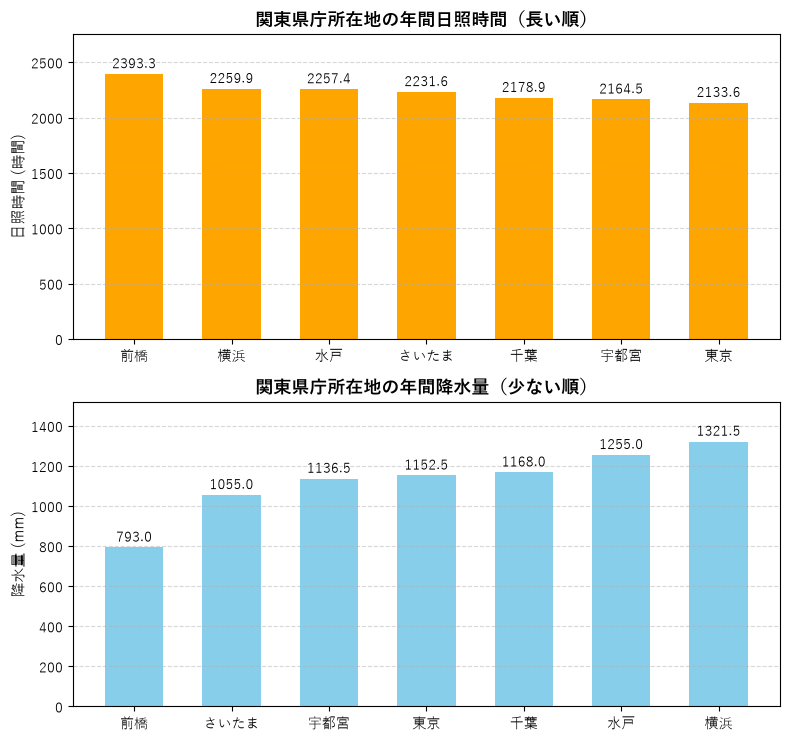

In [13]:
import matplotlib.pyplot as plt

# フォントと背景・文字色の設定（ダークテーマでもクッキリ見えるように白背景を指定）
plt.rcParams["font.family"] = ["Yu Gothic", "Meiryo", "MS Gothic"]
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["text.color"] = "black"
plt.rcParams["axes.labelcolor"] = "black"
plt.rcParams["xtick.color"] = "black"
plt.rcParams["ytick.color"] = "black"

# 日照時間が長い順に並べ替えたデータ
sorted_sun = sorted(results, key=lambda x: x["年間日照時間"], reverse=True)
cities_sun = [r["都市"] for r in sorted_sun]
sun_values = [r["年間日照時間"] for r in sorted_sun]

# 降水量が少ない順に並べ替えたデータ
sorted_rain = sorted(results, key=lambda x: x["年間降水量"])
cities_rain = [r["都市"] for r in sorted_rain]
rain_values = [r["年間降水量"] for r in sorted_rain]

# グラフを上下2つ並べて描画
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7.5))

# 上段：年間日照時間
bars1 = ax1.bar(cities_sun, sun_values, color="orange", width=0.6)
ax1.set_title("関東県庁所在地の年間日照時間（長い順）", fontsize=13, fontweight="bold")
ax1.set_ylabel("日照時間 (時間)", fontsize=11)
ax1.set_ylim(0, max(sun_values) * 1.15)  # 上に余白を作る
ax1.grid(axis="y", linestyle="--", alpha=0.5)
ax1.bar_label(bars1, fmt="%.1f", padding=3, fontsize=10)  # 棒の上に数値を表示

# 下段：年間降水量
bars2 = ax2.bar(cities_rain, rain_values, color="skyblue", width=0.6)
ax2.set_title("関東県庁所在地の年間降水量（少ない順）", fontsize=13, fontweight="bold")
ax2.set_ylabel("降水量 (mm)", fontsize=11)
ax2.set_ylim(0, max(rain_values) * 1.15)  # 上に余白を作る
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.bar_label(bars2, fmt="%.1f", padding=3, fontsize=10)  # 棒の上に数値を表示

plt.tight_layout()
plt.show()


## 4. 分析結果の解釈と気づき
1. **「前橋」が日照時間・降水量の両面で圧倒的1位**

   　前橋は年間日照時間が **2393.3時間** と7都市中最も長く、年間降水量も **793.0mm** で最も少ない結果となった。特に降水量は2位のさいたま（1055.0mm）と比較しても約260mm少なく、天候リスクが極めて低い都市といえる。

2. **「横浜」は日照時間が多い一方で降水量も最多**

   　横浜は日照時間が **2259.9時間（2位）** と上位であるが、降水量は **1321.5mm（7位・最多）** となった。普段は晴れているときが多いものの、台風や集中豪雨など「降るときにまとまった雨が降る」傾向があると考えられる。

3. **東京は日照時間が最も短い**

   　東京の年間日照時間は **2133.6時間** で7都市中最も短く、内陸部（前橋・さいたま）と比較して日照時間に約100〜260時間の差が見られました。

---

## 5. 結論と組織への提案

* **最優先の開催・出店候補地は「前橋（群馬県）」を推奨**

  「晴れの日が多く、雨が極端に少ない」という条件は前橋が一番あてはまり、屋外イベントやキャンプ・グランピング企画に最適です。都心からのアクセスも良く、天候の安定に特化したイベントが有効である。

* **「横浜」での開催は季節の選定が重要**

  　横浜は晴天率の高い一方、総降水量が多いため、梅雨や台風シーズンを避けた春・秋のピンポイント開催に絞るとよい。

### データの限界と今後の課題

* 本分析は **2025年1年間の月別データ** に基づいており、特定の月の記録的豪雨などの影響を受けている可能性があり、より確実な判断をするには、過去5〜10年分の平均データとの比較が必要。

　また、月ごとの合計値であるため、「平日に雨が降り、週末は晴れていた」といった曜日別の傾向までは把握できていない。
